In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

import pickle
import os


In [2]:
### Read CSV
df = pd.read_csv('insurance.csv')
print('Data shape:', df.shape)
print('Columns:', df.columns.tolist())
df.head()


Data shape: (1338, 7)
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
### Data Information & Check Missing Values
print(df.info())
print(df.describe())
print('Duplicate rows:', df.duplicated().sum())
print('Missing values per column:\n', df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000

In [4]:
### Encode Categorical Variables into Numbers
# Categorical columns: sex (female/male), smoker (yes/no), region (northeast, etc.)
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
print("Categorical columns:", cat_cols)

# One-hot encode with pd.get_dummies (drop_first=True avoids multicollinearity)
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)
print("Encoded columns:", df_encoded.columns.tolist())
df_encoded.head()


Categorical columns: ['sex', 'smoker', 'region']
Encoded columns: ['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [5]:
### Feature (X) and Target (y) Separation
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

print('Features shape:', X.shape)
print('Target shape:', y.shape)
print(f"Target 'charges' - Min: ${y.min():,.2f}, Mean: ${y.mean():,.2f}, Max: ${y.max():,.2f}")


Features shape: (1338, 8)
Target shape: (1338,)
Target 'charges' - Min: $1,121.87, Mean: $13,270.42, Max: $63,770.43


In [6]:
### Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training samples: {X_train.shape[0]}')
print(f'Testing samples:  {X_test.shape[0]}')


Training samples: 1070
Testing samples:  268


In [7]:
### Feature Scaling (StandardScaler)
# KNN calculates distance between data points, so scaling all features is essential!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [8]:
### Baseline KNN Regressor (k=5)
baseline_knn = KNeighborsRegressor(n_neighbors=5)
baseline_knn.fit(X_train_scaled, y_train)

y_pred_baseline = baseline_knn.predict(X_test_scaled)

print(f'Baseline R² Score: {r2_score(y_test, y_pred_baseline):.4f}')
print(f'Baseline MAE:      ${mean_absolute_error(y_test, y_pred_baseline):,.2f}')
print(f'Baseline RMSE:     ${root_mean_squared_error(y_test, y_pred_baseline):,.2f}')


Baseline R² Score: 0.8038
Baseline MAE:      $3,494.75
Baseline RMSE:     $5,519.05


Best K from CV: 9 with Mean CV R² = 0.7735


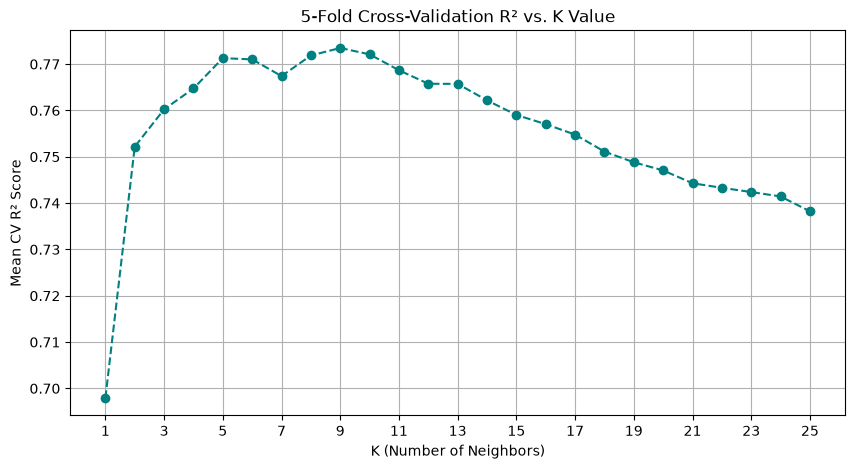

In [9]:
### Find Optimal K using 5-Fold Cross-Validation
k_range = range(1, 26)
cv_r2_scores = []

for k in k_range:
    knn = KNeighborsRegressor(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='r2')
    cv_r2_scores.append(scores.mean())

best_k = k_range[np.argmax(cv_r2_scores)]
print(f'Best K from CV: {best_k} with Mean CV R² = {max(cv_r2_scores):.4f}')

# Plotting CV R² vs K
plt.figure(figsize=(10, 5))
plt.plot(k_range, cv_r2_scores, marker='o', linestyle='dashed', color='teal')
plt.title('5-Fold Cross-Validation R² vs. K Value')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Mean CV R² Score')
plt.xticks(range(1, 26, 2))
plt.grid(True)
plt.show()


In [10]:
### Hyperparameter Tuning using GridSearchCV
# Tuning n_neighbors, weights (uniform vs distance), and metric (euclidean vs manhattan)
param_grid = {
    'n_neighbors': list(range(1, 26)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_search = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)

print('Best Parameters:', grid_search.best_params_)
print(f'Best CV R² Score: {grid_search.best_score_:.4f}')


Best Parameters: {'metric': 'euclidean', 'n_neighbors': 10, 'weights': 'distance'}
Best CV R² Score: 0.7832


Test R² Score: 0.8150
Test MAE:      $3,324.07
Test RMSE:     $5,359.59


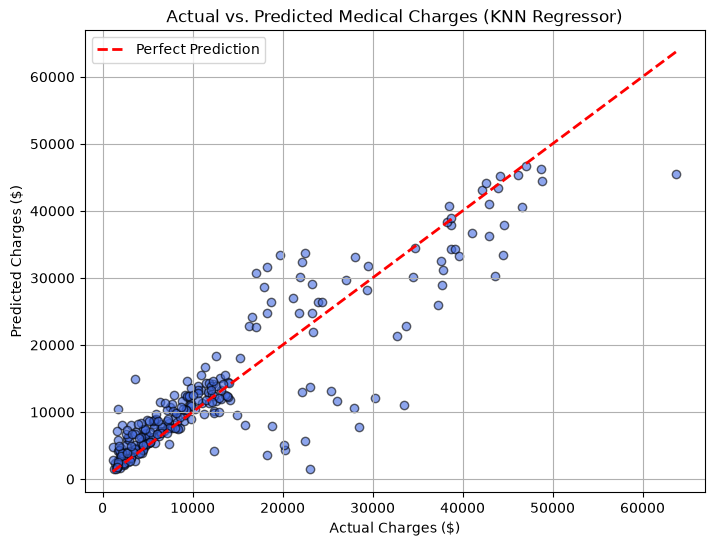

In [11]:
### Evaluate Best KNN Regressor on Test Set
best_knn = grid_search.best_estimator_
y_pred = best_knn.predict(X_test_scaled)

test_r2 = r2_score(y_test, y_pred)
test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = root_mean_squared_error(y_test, y_pred)

print(f'Test R² Score: {test_r2:.4f}')
print(f'Test MAE:      ${test_mae:,.2f}')
print(f'Test RMSE:     ${test_rmse:,.2f}')

# Plot Actual vs. Predicted Charges
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='royalblue', edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Charges ($)')
plt.ylabel('Predicted Charges ($)')
plt.title('Actual vs. Predicted Medical Charges (KNN Regressor)')
plt.legend()
plt.grid(True)
plt.show()


In [12]:
### Build End-to-End Pipeline & Save Model
# Chaining StandardScaler and the best KNN regressor into a single pipeline
final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', best_knn)
])
final_pipeline.fit(X_train, y_train)

model_filename = 'final_knn_regressor.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(final_pipeline, file)

print(f"Model pipeline saved successfully to '{model_filename}'")


Model pipeline saved successfully to 'final_knn_regressor.pkl'


In [13]:
### Load and Verify Saved Model
with open(model_filename, 'rb') as file:
    loaded_model = pickle.load(file)

print('Model loaded successfully!')
print('Model file exists:', os.path.exists(model_filename))

# Verify predictions match
sample_actual = y_test.iloc[:5].values
sample_pred_orig = final_pipeline.predict(X_test.iloc[:5])
sample_pred_load = loaded_model.predict(X_test.iloc[:5])

results_df = pd.DataFrame({
    'Actual Charges': [f'${val:,.2f}' for val in sample_actual],
    'Original Pred':  [f'${val:,.2f}' for val in sample_pred_orig],
    'Loaded Pred':    [f'${val:,.2f}' for val in sample_pred_load]
})
print('\nSample Predictions Comparison (first 5 test samples):')
print(results_df)
print('\nDo predictions match perfectly?:', np.allclose(sample_pred_orig, sample_pred_load))


Model loaded successfully!
Model file exists: True

Sample Predictions Comparison (first 5 test samples):
  Actual Charges Original Pred Loaded Pred
0      $9,095.07     $8,734.15   $8,734.15
1      $5,272.18     $5,671.48   $5,671.48
2     $29,330.98    $28,234.96  $28,234.96
3      $9,301.89    $10,500.30  $10,500.30
4     $33,750.29    $22,766.99  $22,766.99

Do predictions match perfectly?: True
